# Network Gene Usage Extras

Complementary views of the same model as `Network Gene Usage.ipynb`: Structure 3 fitted on all 1,849 patients, everything reported on all patients. These analyses are not part of the article. The Shapley values come from the cache written by the other notebook.

```
S(t | x) = p + (1 - p) S1(t),    z = (log t - mu) / sigma
mu       = z_mu · beta_mu                   linear in age, NPI, PAM50
sigma    = exp(z_sigma · beta_sigma)        linear in PAM50
logit(p) = z_p · beta_p + NN(genes)         linear in age, NPI, PAM50, plus a network on the 173 gene counts
```

`NN(genes)` is called `p_nn`. A positive `p_nn` raises the cure odds and a negative one lowers them.

Sections:

1. Size of the gene effect.
2. Survival curves with and without the genes.
3. Do the rarest genes get the largest push?
4. Relation to PAM50.
5. Control structure: the cure effect of the subtypes with and without the network.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import norm, spearmanr
from scipy.special import expit, logit
from sklearn.manifold import TSNE
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold
import lifelines
from lifelines.utils import concordance_index

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import thetaflow as thf

sys.path.insert(0, "../src")
from package import cure_aft, evaluation_metrics

DIST = "ln"
CACHE_DIR = Path(os.environ.get("DSA_CACHE", "../results/gene_effect"))
CACHE_DIR.mkdir(parents = True, exist_ok = True)
WEIGHTS_DIR = Path("../model_weights/Interpretability")

SUBTYPES = ["LumA", "LumB", "Her2", "Basal", "claudin-low", "Normal"]
SUBTYPE_COLOR = dict(zip(SUBTYPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
NEG, POS, NS = "#e34948", "#2a78d6", "#b9b8b2"
DIRECTION_COLOR = {"lowers cure odds": NEG, "not significant": NS, "raises cure odds": POS}
DIVERGING = LinearSegmentedColormap.from_list("neg_pos", [NEG, "#e5e4e0", POS])

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9, "legend.frameon": False,
})

/home/tonso/code/nhilariosilva/metabric_aft_models/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


I0000 00:00:1794002542.896121  872234 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794002543.514435  872234 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Data and models

In [2]:
clean = pd.concat([pd.read_csv("../data/00_clean/metabric_train_data.csv"), pd.read_csv("../data/00_clean/metabric_test_data.csv")], ignore_index = True)
df = pd.concat([pd.read_csv("../data/01_mlready/metabric_train.csv"), pd.read_csv("../data/01_mlready/metabric_test.csv")], ignore_index = True)
assert (clean["patient_id"] == df["patient_id"]).all()

y, delta, X = df["time"] / 12, df["delta"], df.iloc[:, 10:]
subtype = clean["pam50_subtype"]
z_mu = df.iloc[:, 3:10].copy()
z_mu.insert(0, "const", 1.0)
z_sigma = df.iloc[:, 5:10].copy()
z_sigma.insert(0, "const", 1.0)
z_p = df.iloc[:, 3:10].copy()
z_p1 = z_p.copy()
z_p1.insert(0, "const", 1.0)
n_mutated = (X > 0).sum(axis = 1)
print(f"{len(df)} patients ({int(delta.sum())} events), {X.shape[1]} genes, all used to fit the model")

params3, loss3, survival_cure3 = cure_aft.build_cure_aft_structure3(DIST, z_mu, z_sigma, z_p)
NN_ARCH = (cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast)
model3 = thf.ModelNN(params3, loss3, *NN_ARCH, input_dim = (X.shape[1],), seed = 10)
model3.load_model(str(WEIGHTS_DIR / f"{DIST}_model_structure3"))

params1, loss1, survival_cure1 = cure_aft.build_cure_aft_structure1(DIST, z_mu, z_sigma, z_p1)
model1 = thf.ModelNN(params1, loss1, seed = 10)
model1(None)
model1.load_model(str(WEIGHTS_DIR / f"{DIST}_model_structure1"))

def predict3(X_counts):
    """Forecast of Structure 3 for every patient, with the gene counts replaced by X_counts."""
    return survival_cure3(model3, y, delta, X, z_mu, z_sigma, z_p, y, delta, X_counts, z_mu, z_sigma, z_p, ngrid = 100)

def survival_at(summary, t):
    grid, S = summary["ts_grid"].ravel(), summary["S_ts_test"]
    return np.array([np.interp(t, grid, S[:, j]) for j in range(S.shape[1])])

WITH = predict3(X)
ZERO = predict3(X * 0)
STRUCTURE1 = survival_cure1(model1, y, delta, z_mu, z_sigma, z_p1, y, delta, z_mu, z_sigma, z_p1, ngrid = 100)
REFERENCES = {"zero-out": ZERO, "Structure 1": STRUCTURE1}

GENE = model3.summary(X).iloc[:, -4:].reset_index(drop = True)
GENE["significant"] = (GENE["p_nn_lower"] > 0) | (GENE["p_nn_upper"] < 0)
GENE["direction"] = np.where(~GENE["significant"], "not significant", np.where(GENE["p_nn"] > 0, "raises cure odds", "lowers cure odds"))
print(f"{GENE['significant'].mean():.1%} of the patients have a gene effect whose 95% interval excludes 0")

shap_path = CACHE_DIR / "shap_all_bg100.npy"
assert shap_path.exists(), "run the Shapley section of Network Gene Usage.ipynb first"
shap_values = np.load(shap_path)
genes = np.array(X.columns)
carriers = (X > 0).sum()
importance = pd.Series(np.abs(shap_values).mean(axis = 0), index = genes).sort_values(ascending = False)

1849 patients (754 events), 173 genes, all used to fit the model


Model successfully loaded from ../model_weights/Interpretability/ln_model_structure3.
Model successfully loaded from ../model_weights/Interpretability/ln_model_structure1.


28.6% of the patients have a gene effect whose 95% interval excludes 0


## 1. Size of the gene effect

Each patient has one gene effect `p_nn` on the cure logit, with a 95% interval from a last-layer Laplace approximation. The interval conditions on this single fit, so it is narrower than the full uncertainty. A patient is called significant when the interval excludes 0. The clinical part of the cure logit has no constant term, so the network also carries the baseline cure level.

In [3]:
Z = z_p.to_numpy()
display(pd.Series({
    "mean of p_nn": GENE["p_nn"].mean(),
    "SD of p_nn": GENE["p_nn"].std(),
    "share with an interval excluding 0": GENE["significant"].mean(),
    "share that lowers the cure odds": (GENE["direction"] == "lowers cure odds").mean(),
    "share that raises the cure odds": (GENE["direction"] == "raises cure odds").mean(),
    "variance of p_nn explained by the clinical variables": LinearRegression().fit(Z, GENE["p_nn"]).score(Z, GENE["p_nn"]),
    "correlation of p_nn with the number of mutated genes": np.corrcoef(GENE["p_nn"], n_mutated)[0, 1],
}, name = "all patients").round(3).to_frame())

,all patients
mean of p_nn,-1.171
SD of p_nn,1.269
share with an interval excluding 0,0.286
share that lowers the cure odds,0.242
share that raises the cure odds,0.043
variance of p_nn explained by the clinical variables,0.017
correlation of p_nn with the number of mutated genes,-0.389


## 2. Survival curves with and without the genes

Mean predicted survival by subtype with the genes (solid) and without them (dashed), against the Kaplan-Meier curve with its 95% band. "Without" is the zero-out and the Structure 1 forecast, as in the main notebook.

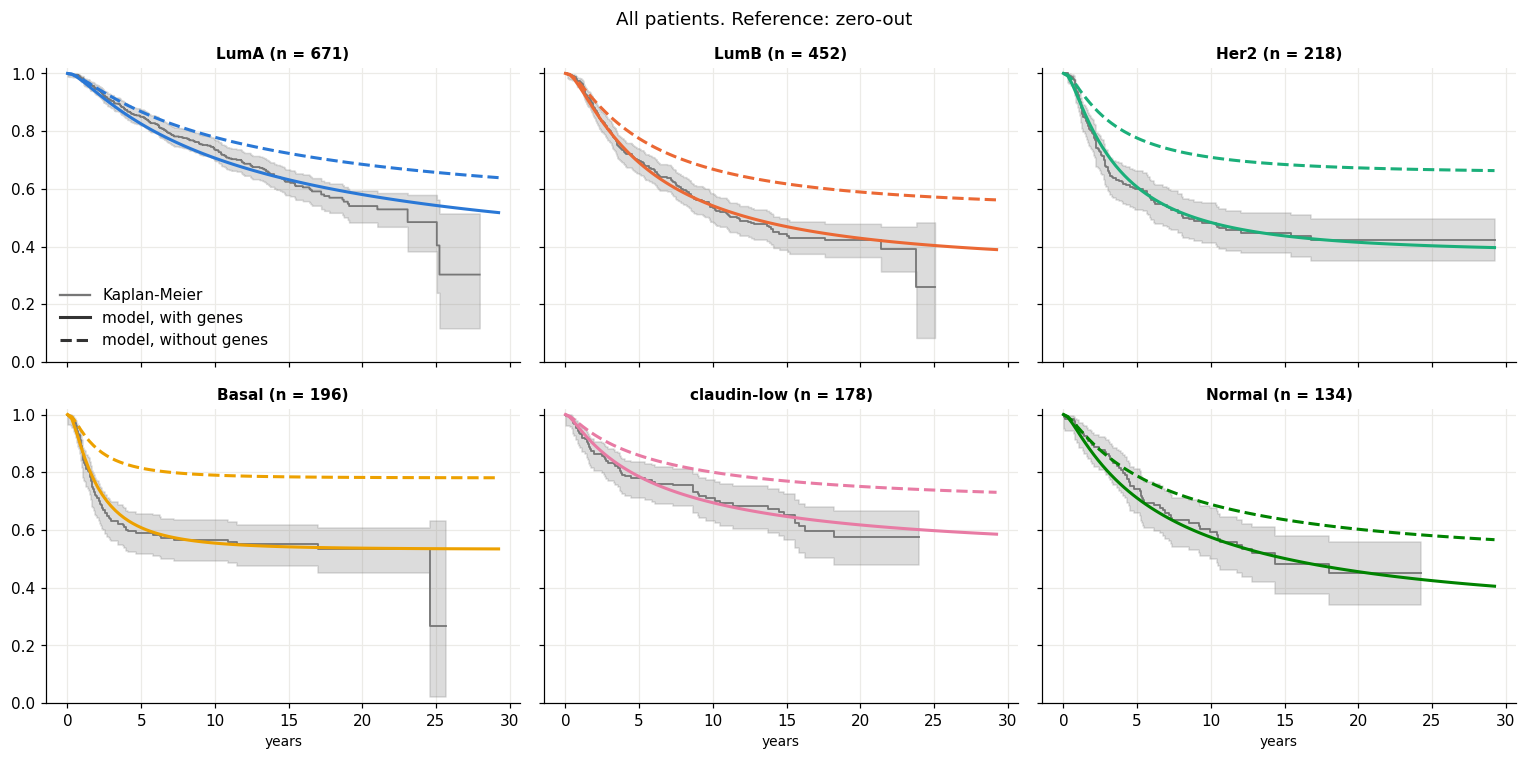

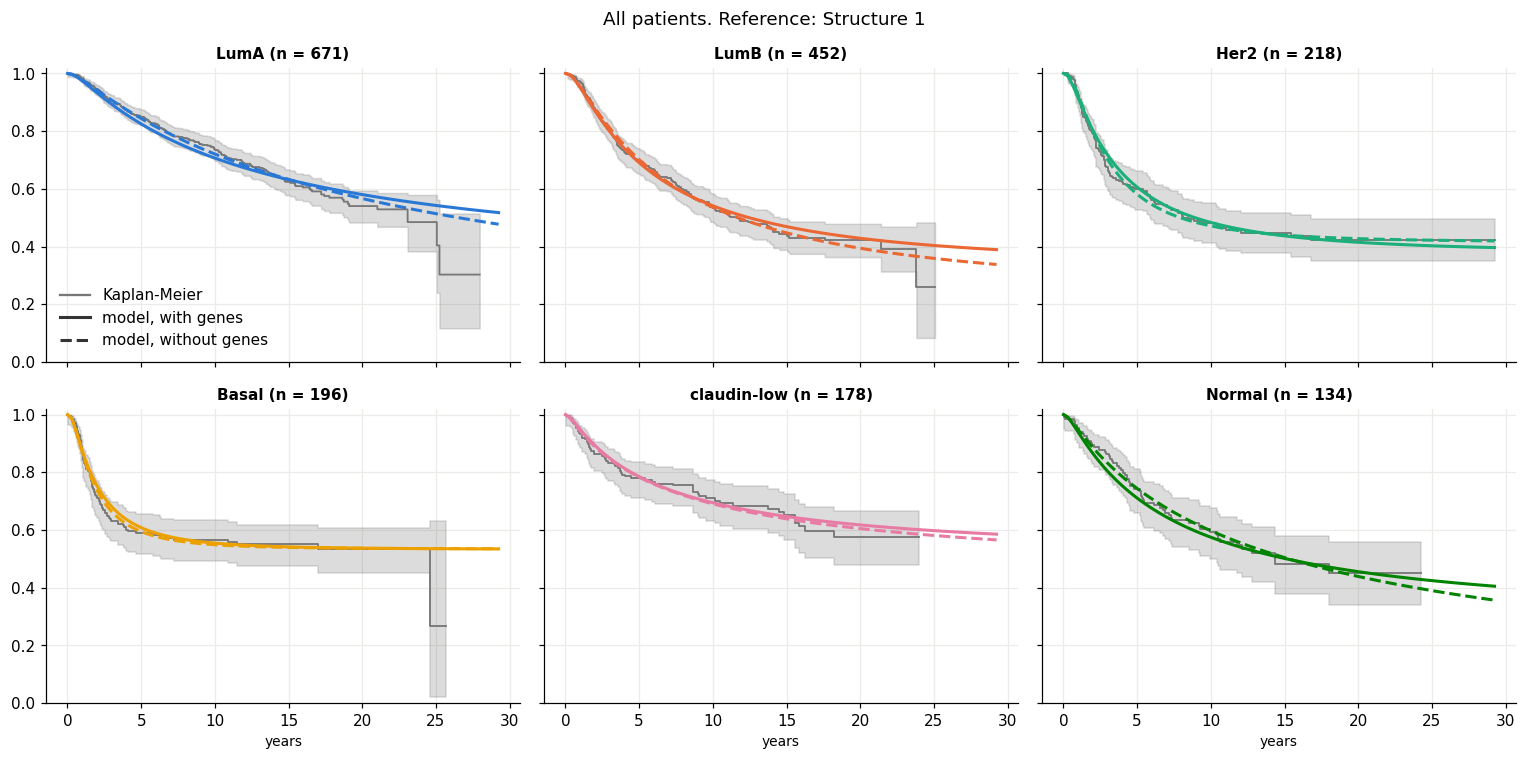

In [4]:
def survival_curves(name):
    ref, grid = REFERENCES[name], WITH["ts_grid"].ravel()
    fig, ax = plt.subplots(2, 3, figsize = (14, 7), sharex = True, sharey = True)
    for a, s in zip(ax.ravel(), SUBTYPES):
        mask = (subtype == s).to_numpy()
        lifelines.KaplanMeierFitter().fit(y[mask], delta[mask]).plot_survival_function(ax = a, ci_show = True, color = "#777777", lw = 1.2, legend = False)
        a.plot(grid, WITH["S_ts_test"][:, mask].mean(axis = 1), color = SUBTYPE_COLOR[s], lw = 2)
        a.plot(grid, ref["S_ts_test"][:, mask].mean(axis = 1), color = SUBTYPE_COLOR[s], lw = 2, ls = "--")
        a.set_title(f"{s} (n = {mask.sum()})")
        a.set_ylim(0, 1.02)
        a.set_xlabel("years")
    ax[0, 0].legend(handles = [Line2D([], [], color = "#777777", label = "Kaplan-Meier"),
                               Line2D([], [], color = "#333333", lw = 2, label = "model, with genes"),
                               Line2D([], [], color = "#333333", lw = 2, ls = "--", label = "model, without genes")], loc = "lower left")
    fig.suptitle(f"All patients. Reference: {name}")
    fig.tight_layout()
    plt.show()

for name in REFERENCES:
    survival_curves(name)

## 3. Do the rarest genes get the largest push?

Each point is a gene mutated in at least 3 patients. The horizontal axis is the number of patients who carry it and the vertical axis is the average Shapley value among those carriers. If the network fits noise, the largest pushes come from the rarest genes. All patients were used to fit the network, so this is an in-sample view.

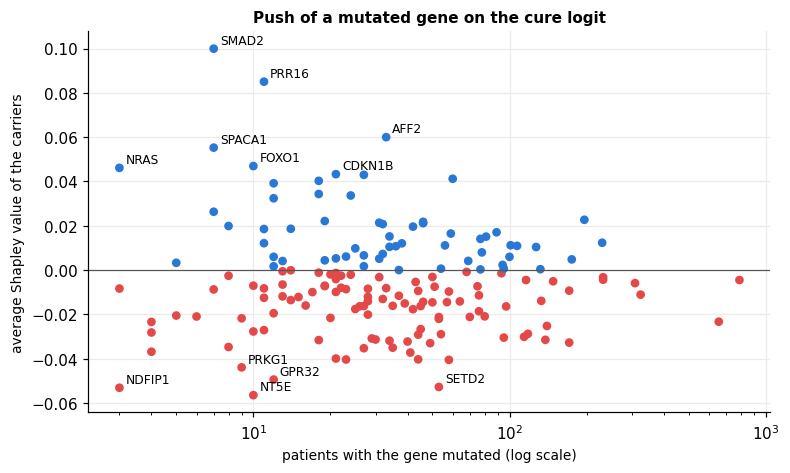

Spearman correlation between |push| and the number of carriers: -0.189 (p = 0.0143), 168 genes with at least 3 carriers


In [5]:
mutated = (X > 0).to_numpy()
push = pd.DataFrame({
    "carriers": carriers.to_numpy(),
    "push": [shap_values[mutated[:, j], j].mean() if carriers.iloc[j] >= 3 else np.nan for j in range(len(genes))],
}, index = genes).dropna()

fig, ax = plt.subplots(figsize = (8, 4.5))
ax.scatter(push["carriers"], push["push"], c = np.where(push["push"] > 0, POS, NEG), s = 22)
ax.set_xscale("log")
ax.axhline(0, color = "#555555", lw = 0.8)
for g in push["push"].abs().sort_values(ascending = False).index[:12]:
    ax.annotate(g, (push.loc[g, "carriers"], push.loc[g, "push"]), xytext = (4, 3), textcoords = "offset points", fontsize = 8)
ax.set_xlabel("patients with the gene mutated (log scale)")
ax.set_ylabel("average Shapley value of the carriers")
ax.set_title("Push of a mutated gene on the cure logit")
plt.show()

rho, p = spearmanr(push["push"].abs(), push["carriers"])
print(f"Spearman correlation between |push| and the number of carriers: {rho:.3f} (p = {p:.3g}), {len(push)} genes with at least 3 carriers")

## 4. Relation to PAM50

The heatmaps show, for the 15 genes with the largest mean |Shapley value|, how often each gene is mutated in each subtype and how much it pushes the cure logit on average in each subtype. The scatter shows the gene effect of every patient against NPI.

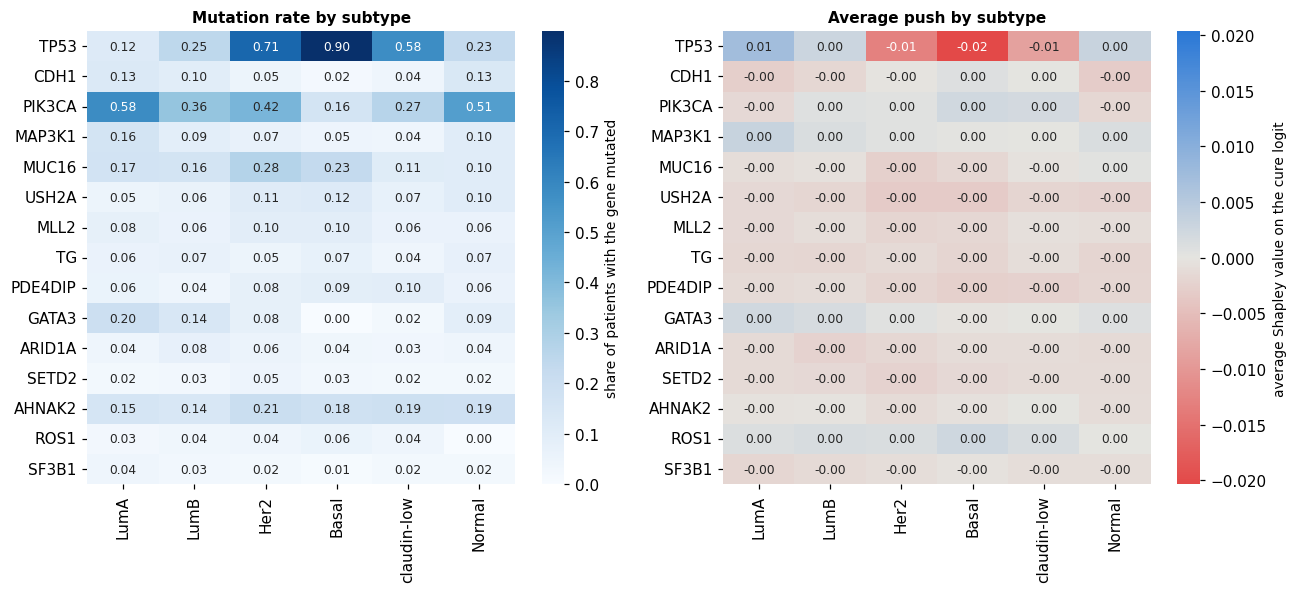

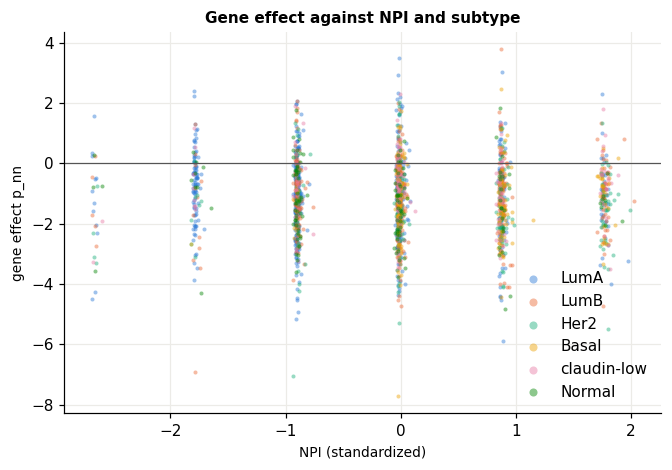

In [6]:
top_genes = list(importance.index[:15])
mutated_rate = (X[top_genes] > 0).groupby(subtype.to_numpy()).mean().loc[SUBTYPES].T
mean_shap = pd.DataFrame(shap_values[:, [list(genes).index(g) for g in top_genes]], columns = top_genes).groupby(subtype.to_numpy()).mean().loc[SUBTYPES].T

fig, ax = plt.subplots(1, 2, figsize = (12, 5.5))
sns.heatmap(mutated_rate, cmap = "Blues", vmin = 0, annot = True, fmt = ".2f", annot_kws = {"size": 8}, cbar_kws = {"label": "share of patients with the gene mutated"}, ax = ax[0])
ax[0].set_title("Mutation rate by subtype")
limit = mean_shap.abs().to_numpy().max()
sns.heatmap(mean_shap, cmap = DIVERGING, center = 0, vmin = -limit, vmax = limit, annot = True, fmt = ".2f", annot_kws = {"size": 8},
            cbar_kws = {"label": "average Shapley value on the cure logit"}, ax = ax[1])
ax[1].set_title("Average push by subtype")
for a in ax:
    a.set_xlabel("")
    a.grid(False)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize = (7, 4.5))
for s in SUBTYPES:
    mask = (subtype == s).to_numpy()
    ax.scatter(z_p["npi"][mask], GENE["p_nn"][mask], s = 7, alpha = 0.45, color = SUBTYPE_COLOR[s], label = s, lw = 0)
ax.axhline(0, color = "#555555", lw = 0.8)
ax.set_xlabel("NPI (standardized)")
ax.set_ylabel("gene effect p_nn")
ax.set_title("Gene effect against NPI and subtype")
ax.legend(markerscale = 2)
plt.show()

## 5. Control structure: the cure effect of the subtypes with and without the network

Structure 1 has the same loss and the same clinical variables as Structure 3 and no network, with a constant in the cure part. The table and plot compare the cure log-odds of each subtype relative to LumA in three versions: Structure 1, the clinical part of Structure 3, and the clinical part of Structure 3 plus the average gene effect of the subtype. The cure part and the timing part trade off in these fits, so the comparison is descriptive.

,Structure 1 (no genes),"Structure 3, clinical part","Structure 3, clinical part + average gene effect of the subtype"
Basal,3.41,1.72,1.52
Her2,2.79,1.01,0.62
LumB,1.80,0.31,0.27
Normal,-0.19,-0.00,-0.19
claudin-low,2.89,1.09,1.29


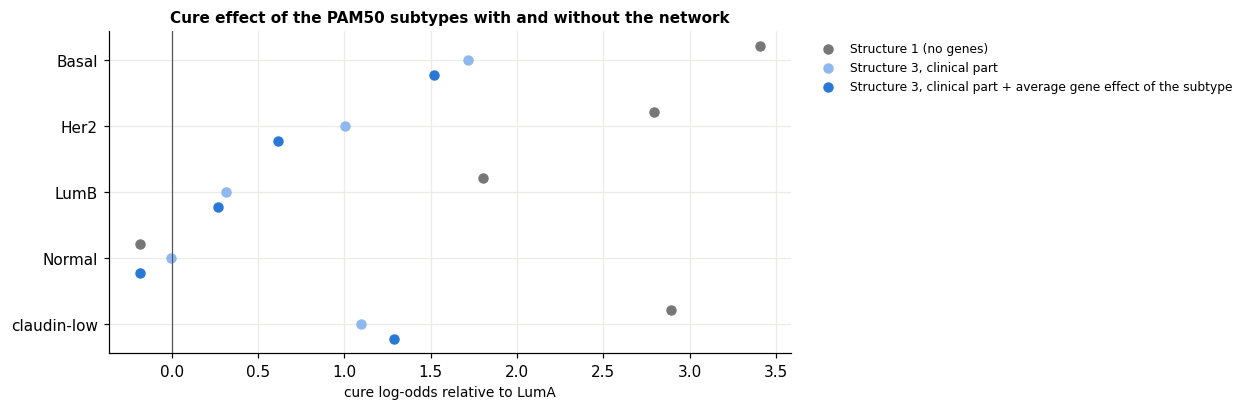

In [7]:
dummies = [c for c in z_p.columns if c.startswith("pam50_subtype_")]
names = [c.removeprefix("pam50_subtype_") for c in dummies]
beta1 = pd.Series(model1.predict("p_beta"), index = z_p1.columns)
beta3 = pd.Series(model3.predict("p_beta"), index = z_p.columns)
offset = GENE["p_nn"].groupby(subtype.to_numpy()).mean()
compare = pd.DataFrame({
    "Structure 1 (no genes)": beta1[dummies].to_numpy(),
    "Structure 3, clinical part": beta3[dummies].to_numpy(),
    "Structure 3, clinical part + average gene effect of the subtype": beta3[dummies].to_numpy() + (offset[names] - offset["LumA"]).to_numpy(),
}, index = names)
display(compare.round(2))

fig, ax = plt.subplots(figsize = (8, 3.8))
pos = np.arange(len(names))[::-1]
for shift, (col, color) in zip((0.22, 0, -0.22), zip(compare.columns, ("#777777", "#8fb8ee", POS))):
    ax.scatter(compare[col], pos + shift, color = color, s = 34, label = col)
ax.axvline(0, color = "#555555", lw = 0.8)
ax.set_yticks(pos, names)
ax.set_xlabel("cure log-odds relative to LumA")
ax.set_title("Cure effect of the PAM50 subtypes with and without the network")
ax.legend(fontsize = 8, loc = "upper left", bbox_to_anchor = (1.02, 1))
plt.show()